# Machine-Learning Smart Beta with No-Trade Band Sweep


## Strategy overview

This strategy was born and developed from a classical smart beta inverse volatility portfolio with liquidity constraints. Through an ML enhancement, a risk restructuring and the application of a band to restrict turnover, it morphed into a more innovative, sensible and robust alternative. More specifically, this long-only equity strategy was extended into a global-minimum-variance (GMV) design with a directional machine-learning tilt.

Two estimation problems were treated separately and then combined at each quarterly rebalancing date:
- **Expected return** is captured only as a relative ranking signal (a predicted percentile, not a return forecast) and used to tilt the portfolio without driving it.
- **Risk** is estimated with a full, shrinkage-based covariance matrix (Ledoit-Wolf method) rather than each stock's own historical volatility in isolation, so that correlation across stocks and not just individual variance is taken into account when determining the weights.

The resulting equity portfolio is rebalanced quarterly. The application of a no-trade band ensures limited unnecessary turnover, which is fundamental since it is evaluated net of realistic transaction and holding costs against the Swiss Performance Index (SPI) benchmark.

## 1.import+ paths

In [1]:
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.covariance import LedoitWolf

def find_repo_root(start=None):
    """Walk up from the notebook folder to the repository root."""
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / 'framework').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate the repository root (folder containing framework/).')


REPO_ROOT = find_repo_root()
DATA_PATH = REPO_ROOT / 'data'
for module_dir in ('framework', 'signals', 'data_utils'):
    if str(REPO_ROOT / module_dir) not in sys.path:
        sys.path.insert(0, str(REPO_ROOT / module_dir))
missing = [f for f in ['market_data.parquet', 'jkp_data.parquet', 'spi_index.csv', 'ml_signal_reg.parquet'] if not (DATA_PATH / f).exists()]
if missing:
    raise FileNotFoundError(f'Missing in {DATA_PATH}: {missing}. See data/README.md.')

print('REPO_ROOT:', REPO_ROOT)
print('DATA_PATH:', DATA_PATH)

REPO_ROOT: <repo>
DATA_PATH: <repo>/data


In [2]:
from helper_functions import load_data_spi, align_market_data_with_jkp_data
from optimization.optimization import Optimization, Objective
from backtesting.backtest import Backtest
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.selection import Selection
from backtesting.backtest_item_builder.bib_classes import (
    SelectionItemBuilder,
    OptimizationItemBuilder,
)
from backtesting.backtest_item_builder.bibfn_selection import (
    bibfn_selection_gaps,
    bibfn_selection_min_volume,
)
from backtesting.backtest_item_builder.bibfn_optimization_data import (
    bibfn_return_series,
)

## 2.data

Three data sources are loaded and aligned to a common set of stock IDs and dates: the first one records daily market data (prices/volumes), the second one JKP firm characteristics (the cross-sectional factors used by the ML signal), and the third one the SPI benchmark series. In addition, a pre-computed ML rank signal (`ml_signal_reg.parquet`), which is the offline output of the cross-sectional regression pipeline described in point 6, is also loaded here, since it's used as an input at every rebalancing date rather than re-estimated inside the backtest.

In [3]:
market_data = pd.read_parquet(DATA_PATH / 'market_data.parquet')
jkp_data = pd.read_parquet(DATA_PATH / 'jkp_data.parquet')
spi = load_data_spi(path=str(DATA_PATH) + os.sep)

ml_signal_path = DATA_PATH / 'ml_signal_reg.parquet'
ml_signal_df = pd.read_parquet(ml_signal_path)
ml_signal_df.columns = ml_signal_df.columns.get_level_values(-1).astype(str)

market_data_ffill, jkp_data = align_market_data_with_jkp_data(
    market_data=market_data,
    jkp_data=jkp_data,
)

data = BacktestData()
data.market_data = market_data_ffill
data.jkp_data = jkp_data
data.bm_series = spi

print('market_data:', data.market_data.shape)
print('jkp_data:', data.jkp_data.shape)
print('SPI:', data.bm_series.index.min().date(), 'to', data.bm_series.index.max().date())

market_data: (1408989, 4)
jkp_data: (83421, 153)
SPI: 1999-01-02 to 2024-04-30


## 3.parameters

Key parameters used throughout the backtest:
- `N_MONTHS = 3`: quarterly rebalancing frequency .
- `FIXED_COSTS` / `VARIABLE_COSTS`: the annual expense drag and per rebalance turnover cost .
- `RETURN_HISTORY_DAYS` / `MIN_RETURN_OBS`: lookback and minimum data requirement for the return history selection filter.
- `GAP_LOOKBACK_DAYS` / `MAX_ZERO_VOLUME_GAP_DAYS`: trading-gap selection filter.
- `LIQUIDITY_LOOKBACK_DAYS` / `MIN_MEDIAN_LIQUIDITY`: liquidity selection filter.
- `RISK_LOOKBACK_DAYS`: lookback window for the Ledoit-Wolf covariance estimate.
- `MAX_STOCK_WEIGHT`: nominal cap applied after combining the GMV and ML signals.
- `BAND_WIDTH` / `RHO`: the no trade band threshold and partial trade restructuring fraction. Both are guesses made before the robustness analysis carried out later.

In [4]:
N_MONTHS = 3
START_DATE = '2003-01-01'

FIXED_COSTS = 0.01
VARIABLE_COSTS = 0.002

RETURN_HISTORY_DAYS = 252 * 2
MIN_RETURN_OBS = 400
GAP_LOOKBACK_DAYS = 365
MAX_ZERO_VOLUME_GAP_DAYS = 21
LIQUIDITY_LOOKBACK_DAYS = 365
MIN_MEDIAN_LIQUIDITY = 500_000
RISK_LOOKBACK_DAYS = 252 * 2
MAX_STOCK_WEIGHT = 0.08
BAND_WIDTH = 0.02
RHO = 0.6

## 4.Builder functions

This section defines the building blocks which the backtest engine calls at each rebalancing date:
- `bibfn_selection_return_history`: implements the return-history selection filter.
- `bibfn_ml_signal`: pulls the most recent available ML rank prediction (`mu_hat`) for the currently selected universe.
- `cap_and_redistribute`: enforces the `MAX_STOCK_WEIGHT` cap by iteratively redistributing excess weight among uncapped names.
- `MLCovTiltedPortfolio`: the core optimization step which fits the Ledoit-Wolf covariance, computes GMV weights, and combines them with the ML tilt as described later.
- `FreshSelectionBacktestService`: ensures the investable universe is rebuilt from scratch at each rebalancing date rather than carrying over state from the previous one.

In [5]:
def current_selected_ids(bs, fallback_index):
    selected = bs.selection.selected
    if selected is None or len(selected) == 0:
        return list(pd.Index(fallback_index).astype(str))
    return list(pd.Index(selected).astype(str))

def bibfn_ml_signal(bs, rebdate, **kwargs):
    ml_signal = kwargs['ml_signal']
    ids = current_selected_ids(bs, ml_signal.columns)
    available = ml_signal.loc[:rebdate]
    if available.empty:
        row = pd.Series(dtype=float).reindex(ids)
    else:
        row = available.iloc[-1].reindex(ids)

    bs.optimization_data['mu_hat'] = row
    return None

def bibfn_selection_return_history(bs, rebdate, **kwargs):
    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=kwargs.get('width', RETURN_HISTORY_DAYS),
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    valid_obs = ret.notna().sum(axis=0)

    return pd.DataFrame({
        'values': valid_obs,
        'binary': (valid_obs >= kwargs.get('min_obs', MIN_RETURN_OBS)).astype(int),
    })
def cap_and_redistribute(weights, cap):
    weights = weights.copy().astype(float)
    if weights.empty:
        return weights
    if len(weights) * cap < 1:
        return weights / weights.sum()

    free = pd.Index(weights.index)
    capped = pd.Series(0.0, index=weights.index)
    remaining = 1.0

    while len(free) > 0:
        scaled = weights.loc[free] / weights.loc[free].sum() * remaining
        over = scaled > cap
        if not over.any():
            capped.loc[free] = scaled
            break
        capped.loc[scaled[over].index] = cap
        remaining = 1.0 - capped.sum()
        free = scaled[~over].index

    return capped / capped.sum()

class MLCovTiltedPortfolio(Optimization):
    def __init__(self, max_weight=MAX_STOCK_WEIGHT, ml_lambda=0.5, **kwargs):
        super().__init__(max_weight=max_weight, solver_name='no-solver-used', **kwargs)
        self.ml_lambda = ml_lambda

    def set_objective(self, optimization_data):
        ret = optimization_data['return_series']

        
        valid_cols = ret.columns[ret.notna().sum() >= MIN_RETURN_OBS]
        ret_clean = ret[valid_cols].fillna(0.0)

        lw = LedoitWolf().fit(ret_clean.values)
        cov = pd.DataFrame(
            lw.covariance_ * 252,  
            index=valid_cols, columns=valid_cols,
        )

        mu_hat = optimization_data['mu_hat'].reindex(valid_cols)

        self.objective = Objective(cov=cov, mu_hat=mu_hat)

    def solve(self):
        cov = self.objective.coefficients['cov']
        mu_hat = self.objective.coefficients['mu_hat'].reindex(cov.index)

        inv_cov = np.linalg.pinv(cov.values)
        ones = np.ones(len(cov))
        w_mv = inv_cov @ ones
        w_mv = pd.Series(w_mv, index=cov.index)
        w_mv = w_mv / w_mv.sum()

        tilt = (mu_hat - 0.5).fillna(0) * 2
        score = w_mv * (1 + self.ml_lambda * tilt)
        score = score.clip(lower=0)  

        weights = score / score.sum()
        weights = cap_and_redistribute(weights, self.params['max_weight'])
        self.results.update({'weights': weights.to_dict(), 'status': True})
        return None
class FreshSelectionBacktestService(BacktestService):
    def build_selection(self, rebdate):
        self.selection = Selection()
        return super().build_selection(rebdate)

## Risk model: Ledoit-Wolf shrinkage covariance.

The classical estimator of a covariance matrix is the sample covariance which is computed directly from the historical returns of the assets in the universe. Unfortunately, the problem is that with `N` assets and `T` return observations, the sample covariance matrix needs `N` to be small relative to `T` to be reliable. That is because when `N` is large relative to `T` (as it is in our case where we have circa 90+ assets versus a 504-day per 2-year window), the sample covariance matrix becomes very noisy, ill-conditioned, and its inverse (which the GMV weights `Σ⁻¹ · 1` depend on directly) becomes numerically unstable. This leads to small estimation errors getting amplified into large, erratic portfolio weights.

Ledoit-Wolf shrinkage addresses this by blending the noisy sample covariance matrix `S` with a simpler, much more stable "target" matrix `F`, which is typically a scaled identity matrix that thus assumes all assets have equal variance and zero correlation. The formulation reads as follows: Σ_shrunk = δ·F + (1 - δ)·S

The shrinkage intensity `δ` , which is normalized between 0 and 1, is not a tuned hyperparameter here, as it is estimated analytically from the data itself, by virtue of minimizing the expected squared distance between `Σ_shrunk` and the (unobservable) true covariance matrix. It follows that the noisier `S` is relative to the amount of data available, the more weight shifts toward the stable target `F`. As such, when there's a lot of data relative to the number of assets, `δ` shrinks toward 0 and `Σ_shrunk` converges back to the sample covariance.

The effect on this strategy is structurally meaningful: because GMV weights are kept from swinging sharply from one rebalance to the next, the no-trade band shows limited but nontheless improved effect when compared to the starting strategy. However, we have to be mindful that even the shrunk covariance estimate still updates meaningfully quarter to quarter, so target weights can shift by more than the band width regardless. Shrinkage doesn't eliminate the turnover driver, but it does make each individual covariance/weight estimate much less sensitive to estimation noise than the raw sample covariance would be. What `scikit-learn`'s `LedoitWolf` implements is this analytical shrinkage-intensity estimator (Ledoit & Wolf, 2004), which is fitted here on the same 2-year return window used elsewhere in the risk pipeline.

## 5.rebalancing dates

Rebalancing dates are derived from the JKP data's own reporting dates, restricted to the period where market data is available, and then thinned to every `N_MONTHS`-th date to get a quarterly schedule. This ties the backtest's trading calendar to when new firm-characteristic data actually becomes available, rather than to an arbitrary calendar grid, and the `START_DATE` cutoff drops the earliest dates where there isn't enough history for the selection filters aforementioned to be meaningful yet.

In [6]:
jkp_dates = data.jkp_data.index.get_level_values('date').unique().sort_values()
market_min_date = data.market_data.index.get_level_values('date').min()
market_max_date = data.market_data.index.get_level_values('date').max()

rebdates = (
    jkp_dates[(jkp_dates > market_min_date) & (jkp_dates <= market_max_date)][::N_MONTHS]
    .strftime('%Y-%m-%d')
    .tolist()
)
rebdates = [date for date in rebdates if date > START_DATE]

print('Number of rebalancing dates:', len(rebdates))
print('First rebalance:', rebdates[0])
print('Last rebalance:', rebdates[-1])

Number of rebalancing dates: 85
First rebalance: 2003-01-31
Last rebalance: 2024-01-31


## 6.backtest

At each rebalancing date, the investable universe is filtered through three sequential criteria:
- **Return history**: at least `MIN_RETURN_OBS` valid daily observations over a 2-year lookback.
- **Trading gaps**: no more than `MAX_ZERO_VOLUME_GAP_DAYS` consecutive zero-volume days within the trailing year.
- **Liquidity**: median daily traded value above `MIN_MEDIAN_LIQUIDITY` over the trailing year.

This typically narrows the JKP universe (~170–190 names with sufficient history) down to roughly 100–115 investable names per quarter. This will further be trimmed by the band imposed later. 

**Expected-return signal.** Expected returns are not estimated in this notebook; they come from a separate, offline cross-sectional ML pipeline (`xsection_regressor.ipynb`) trained on JKP firm characteristics (value, momentum, quality, profitability, leverage, growth, accruals) via Ridge regression on a rolling, walk-forward split. Moreover, the model is only ever trained on data strictly prior to the prediction date to avoid look ahead bias. Its output, `mu_hat`, is a cross-sectional rank in (0, 1) of predicted forward 1-month performance which indicates who is likely to outperform, without really stating by how much.

**Risk model.** As mentioned above, risk is estimated with `sklearn.covariance.LedoitWolf`, fit on the same 2-year window. GMV weights are then computed analytically as `w_mv ∝ Σ⁻¹ · 1` which is the classical minimum-variance portfolio and which downweights redundant (highly correlated) risk and favors diversifying names.

**Combining the two.** The final score is the GMV weight tilted by the ML rank signal: `score_i = w_mv_i * (1 + λ * tilt_i)`, with `tilt_i = 2*(mu_hat_i - 0.5)` recentering the rank to roughly [-1, 1] and `λ = ml_lambda = 0.5`. Negative scores are clipped to zero. This is a long-only heuristic, not an exact constrained solve. After that, they are renormalized, and capped at `MAX_STOCK_WEIGHT = 8%` per name via iterative redistribution.

In [7]:
selection_item_builders = {
    'return_history': SelectionItemBuilder(
        bibfn=bibfn_selection_return_history,
        width=RETURN_HISTORY_DAYS,
        min_obs=MIN_RETURN_OBS,
    ),
    'gaps': SelectionItemBuilder(
        bibfn=bibfn_selection_gaps,
        width=GAP_LOOKBACK_DAYS,
        n_days=MAX_ZERO_VOLUME_GAP_DAYS,
    ),
    'min_volume': SelectionItemBuilder(
        bibfn=bibfn_selection_min_volume,
        width=LIQUIDITY_LOOKBACK_DAYS,
        min_volume=MIN_MEDIAN_LIQUIDITY,
        agg_fn=np.median,
    ),
}
optimization_item_builders = {
    'return_series': OptimizationItemBuilder(
        bibfn=bibfn_return_series,
        width=RISK_LOOKBACK_DAYS,
        weekdays_only=True,
        fillna_value=0,
    ),
    'mu_hat': OptimizationItemBuilder(
        bibfn=bibfn_ml_signal,
        ml_signal=ml_signal_df,
    ),
}
optimization = MLCovTiltedPortfolio(max_weight=MAX_STOCK_WEIGHT, ml_lambda=0.5)

bs_s5 = FreshSelectionBacktestService(
    data=data,
    selection_item_builders=selection_item_builders,
    optimization_item_builders=optimization_item_builders,
    optimization=optimization,
    rebdates=rebdates,
    quiet=False,
)

bt_s5 = Backtest()
bt_s5.run(bs=bs_s5)

weights_s5 = bt_s5.strategy.get_weights_df()
print('Backtest completed.')
print('Weight matrix:', weights_s5.shape)
print('Average holdings:', weights_s5.gt(0).sum(axis=1).mean().round(1))
print('Average max stock weight:', weights_s5.max(axis=1).mean().round(3))
target_weights_df = bt_s5.strategy.get_weights_df()

Rebalancing date: 2003-01-31
Rebalancing date: 2003-04-30
Rebalancing date: 2003-07-31
Rebalancing date: 2003-10-31
Rebalancing date: 2004-01-31
Rebalancing date: 2004-04-30
Rebalancing date: 2004-07-31
Rebalancing date: 2004-10-31
Rebalancing date: 2005-01-31
Rebalancing date: 2005-04-30
Rebalancing date: 2005-07-31
Rebalancing date: 2005-10-31
Rebalancing date: 2006-01-31
Rebalancing date: 2006-04-30
Rebalancing date: 2006-07-31
Rebalancing date: 2006-10-31
Rebalancing date: 2007-01-31
Rebalancing date: 2007-04-30
Rebalancing date: 2007-07-31
Rebalancing date: 2007-10-31
Rebalancing date: 2008-01-31
Rebalancing date: 2008-04-30
Rebalancing date: 2008-07-31
Rebalancing date: 2008-10-31
Rebalancing date: 2009-01-31
Rebalancing date: 2009-04-30
Rebalancing date: 2009-07-31
Rebalancing date: 2009-10-31
Rebalancing date: 2010-01-31
Rebalancing date: 2010-04-30
Rebalancing date: 2010-07-31
Rebalancing date: 2010-10-31
Rebalancing date: 2011-01-31
Rebalancing date: 2011-04-30
Rebalancing da

## 7.NO trade band

Target weights above are only recomputed quarterly. Between rebalances, the actual portfolio is allowed to drift with realized returns rather than being traded back to target immediately. A position is only traded when its drift from target exceeds a band, which is set relative to position size by doing `max(BAND_WIDTH, 25% of target weight)`. Furthermore, only `RHO` of the gap is closed, not the full gap. This is a partial position scaled no-trade band which is intended to cut unnecessary turnover from rebalancing on noise rather than genuine target shifts.

In [8]:
def build_banded_weights(band, rho, return_diagnostics=False):
   
    actual_weights_list = []
    prev_actual_weights = None
    deviations = []
    band_thresholds = []

    for date in target_weights_df.index:
        w_target = target_weights_df.loc[date]

        if prev_actual_weights is None:
            w_final = w_target.copy()
        else:
            last_date = actual_weights_list[-1].name
            period_returns = daily_returns.loc[last_date:date].iloc[1:].add(1).prod() - 1
            w_drift = prev_actual_weights * (1 + period_returns)
            w_drift = w_drift / w_drift.sum()
            w_final = w_drift.copy()

            for asset in w_target.index:
                if pd.isna(w_target[asset]) or w_target[asset] == 0:
                    w_final[asset] = 0.0
                else:
                    band_threshold = np.maximum(band, 0.25 * w_target[asset])
                    deviation = abs(w_target[asset] - w_drift[asset])
                    if return_diagnostics:
                        deviations.append(deviation)
                        band_thresholds.append(band_threshold)
                    if deviation > band_threshold:
                        w_final[asset] = w_drift[asset] + rho * (w_target[asset] - w_drift[asset])

            if w_final.sum() > 0:
                w_final = w_final / w_final.sum()

        w_final.name = date
        actual_weights_list.append(w_final)
        prev_actual_weights = w_final

    weights_df = pd.DataFrame(actual_weights_list)

    if return_diagnostics:
        return weights_df, pd.Series(deviations), pd.Series(band_thresholds)
    return weights_df

In [9]:
daily_returns = data.get_return_series(weekdays_only=True).fillna(0)
s27_weights_df = build_banded_weights(BAND_WIDTH, RHO)

## 8.returns

Net returns are simulated with realistic trading frictions: a variable cost of `VARIABLE_COSTS` (20bp) proportional to turnover at each rebalance, and a fixed cost of `FIXED_COSTS` (1% p.a.) applied as a continuously-accruing daily drag which is an expense ratio, since it accrues regardless of whether the portfolio actually traded. Gross returns are also simulated for comparison, and both are benchmarked against the SPI total-return series.

In [10]:
from backtesting.portfolio import Portfolio
return_series = data.get_return_series(weekdays_only=False)

turnover_s5 = bt_s5.strategy.turnover(return_series=return_series, rescale=False)
turnover_s5.index = pd.to_datetime(turnover_s5.index)




new_portfolios = []
for date in s27_weights_df.index:
    w = s27_weights_df.loc[date].dropna()
    w = w[w != 0]
    new_portfolios.append(Portfolio(rebalancing_date=date, weights=w.to_dict()))

bt_s5.strategy.portfolios = new_portfolios
s27_gross_returns = bt_s5.strategy.simulate(
    return_series=return_series,
    fc=0,
    vc=0,
)
s27_gross_returns.name = 'Strategy gross'

s27_net_returns = bt_s5.strategy.simulate(
    return_series=return_series,
    fc=FIXED_COSTS,
    vc=VARIABLE_COSTS,
)
s27_net_returns.name = 'Strategy net'

comparison = pd.concat(
    {
        'Strategy net': s27_net_returns,
        'Strategy gross': s27_gross_returns,
        'SPI': data.bm_series,
    },
    axis=1,
).dropna()

print(comparison.describe().T)

            count      mean       std       min       25%       50%       75%  \
Strategy net    5609.0  0.000265  0.005923 -0.064364 -0.002264  0.000342  0.003367   
Strategy gross  5609.0  0.000326  0.005923 -0.064324 -0.002209  0.000401  0.003423   
SPI        5609.0  0.000332  0.009932 -0.091109 -0.004052  0.000350  0.005263   

                max  
Strategy net    0.046538  
Strategy gross  0.046577  
SPI        0.105788  


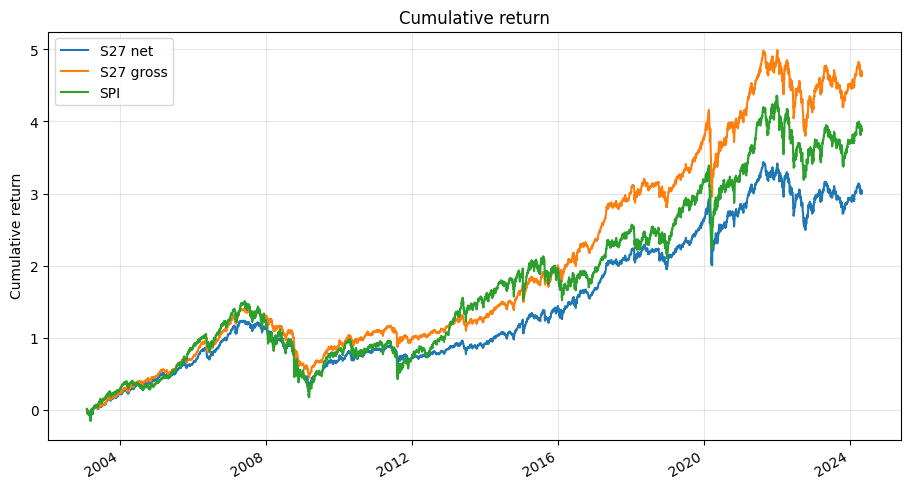

In [11]:
ax = ((1 + comparison).cumprod() - 1).plot(figsize=(11, 6), title='Cumulative return')
ax.set_ylabel('Cumulative return')
ax.grid(alpha=0.3)
plt.show()

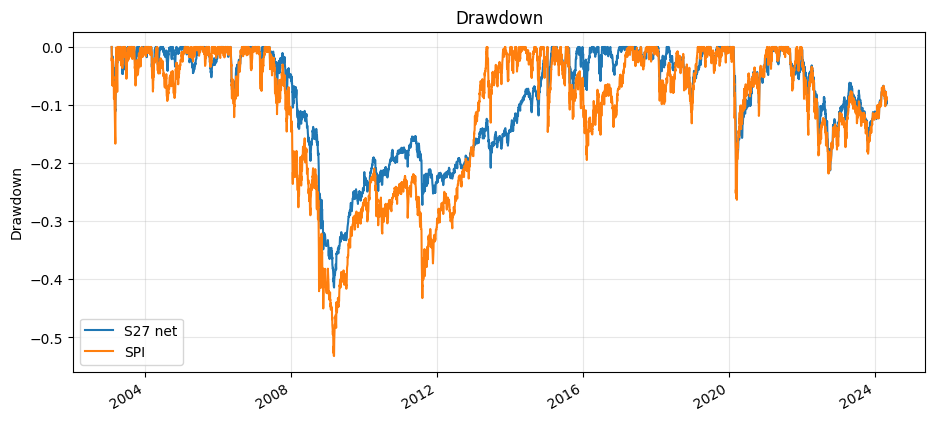

In [12]:
def drawdown(return_df):
    wealth = (1 + return_df).cumprod()
    return wealth / wealth.cummax() - 1


ax = drawdown(comparison[['Strategy net', 'SPI']]).plot(figsize=(11, 5), title='Drawdown')
ax.set_ylabel('Drawdown')
ax.grid(alpha=0.3)
plt.show()

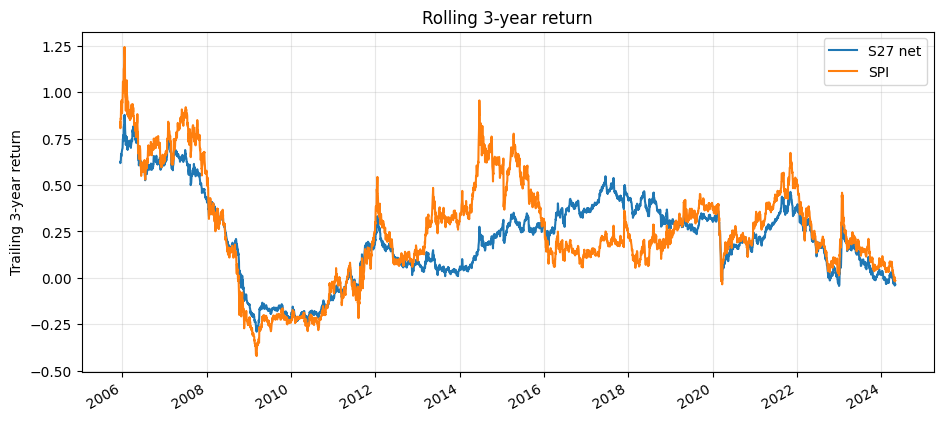

In [13]:
rolling_3y_return = (1 + comparison).rolling(252 * 3).apply(np.prod, raw=True) - 1
ax = rolling_3y_return[['Strategy net', 'SPI']].plot(figsize=(11, 5), title='Rolling 3-year return')
ax.set_ylabel('Trailing 3-year return')
ax.grid(alpha=0.3)
plt.show()

## 8.5 Turnover vs. equity

This chart overlays the net equity curve with turnover at each rebalancing date, to visually check whether trading activity clusters around drawdowns or volatile periods (where the no-trade band would be expected to trigger more often) or is roughly constant through time.

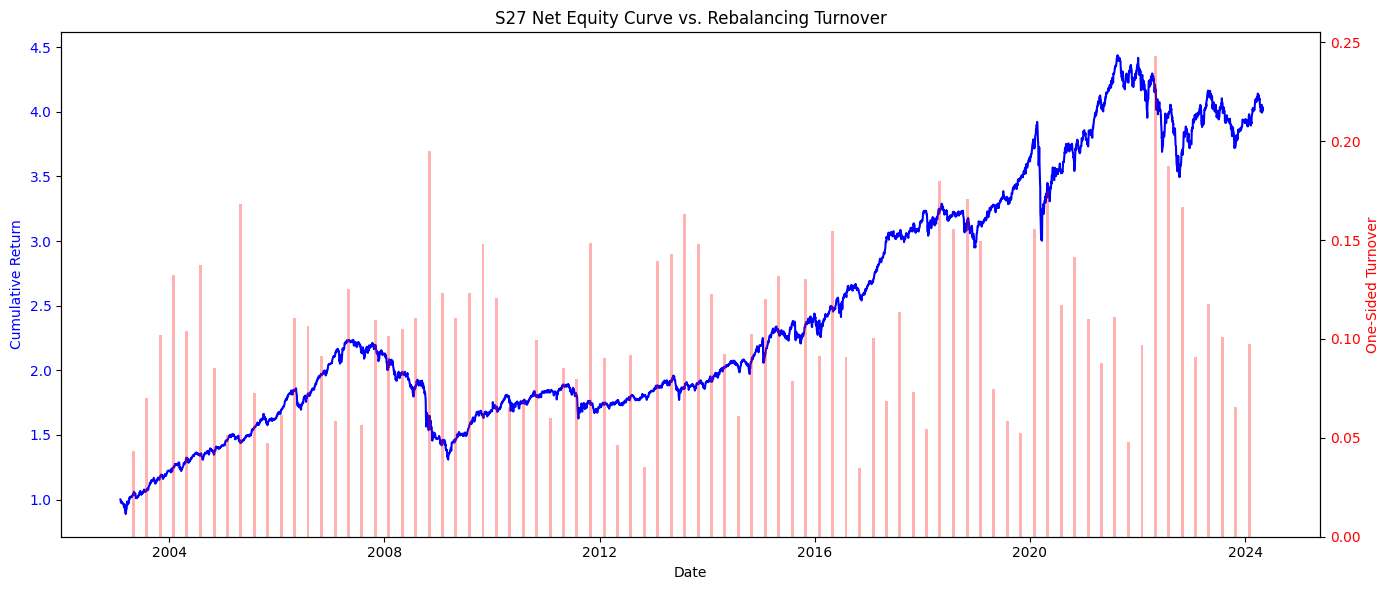

In [14]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd


turnover = s27_weights_df.diff().abs().sum(axis=1) / 2


fig, ax1 = plt.subplots(figsize=(14, 6))


s27_net_cum = (1 + comparison['Strategy net']).cumprod()

s27_net_cum.index = pd.to_datetime(s27_net_cum.index) 
ax1.plot(s27_net_cum.index, s27_net_cum, color='blue', label='Strategy Net Equity')
ax1.set_ylabel('Cumulative Return', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_xlabel('Date')


ax2 = ax1.twinx()


datetime_index = pd.to_datetime(turnover.index)
safe_dates = mdates.date2num(datetime_index.to_pydatetime())


ax2.bar(safe_dates, turnover, color='red', alpha=0.3, width=20, label='Turnover')

ax2.set_ylabel('One-Sided Turnover', color='red')
ax2.tick_params(axis='y', labelcolor='red')


plt.title('Strategy Net Equity Curve vs. Rebalancing Turnover')
fig.tight_layout()
plt.show()

## 9.statistics

Descriptive statistics (annualized return, annualized volatility, Sharpe ratio, max drawdown, daily mean/std) are computed for the full backtest sample and for the trailing 5 years, for the strategy (gross and net) and the SPI benchmark side by side, to check whether performance is stable across the sample or concentrated in a particular sub-period. We witness that in both cases, our strategy outperforms in terms of sharpe ratio the SPI, while being left behind slightly in terms of annualized returns. All in all we think that since the strategy itself is very defensive, as per shown by the smaller drawdowns, such a trade-off is worth to make. 

In [15]:
def annualized_return(r, periods_per_year=252):
    r = r.dropna()
    if len(r) == 0:
        return np.nan
    return (1 + r).prod() ** (periods_per_year / len(r)) - 1


def annualized_volatility(r, periods_per_year=252):
    return r.dropna().std() * np.sqrt(periods_per_year)


def max_drawdown(r):
    dd = drawdown(r.to_frame()).iloc[:, 0]
    return dd.min()


def performance_stats(return_df, periods_per_year=252):
    rows = {}
    for col in return_df.columns:
        r = return_df[col].dropna()
        ann_ret = annualized_return(r, periods_per_year)
        ann_vol = annualized_volatility(r, periods_per_year)
        rows[col] = {
            'annualized_return': ann_ret,
            'annualized_volatility': ann_vol,
            'sharpe_rf0': ann_ret / ann_vol if ann_vol != 0 else np.nan,
            'max_drawdown': max_drawdown(r),
            'daily_mean': r.mean(),
            'daily_std': r.std(),
        }
    return pd.DataFrame(rows).T


full_stats = performance_stats(comparison)
last_5y_stats = performance_stats(comparison.loc[comparison.index >= comparison.index.max() - pd.DateOffset(years=5)])

stats = pd.concat({'Full sample': full_stats, 'Last 5 years': last_5y_stats}, axis=0)
stats.style.format('{:.2%}')

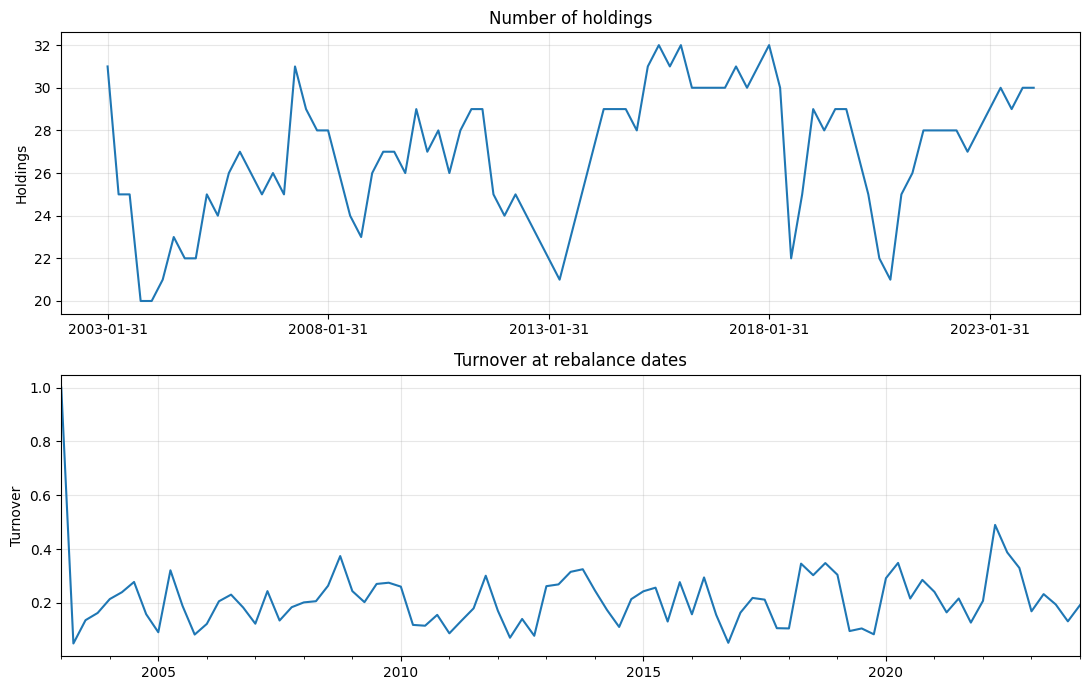

Strategy (Banded) Average turnover: 0.215
Strategy (Banded) Median turnover: 0.206
Strategy (Unbanded Baseline) Average turnover: 0.367
Strategy (Unbanded Baseline) Median turnover: 0.359


In [16]:

turnover_s27 = bt_s5.strategy.turnover(return_series=return_series, rescale=False)
turnover_s27.index = pd.to_datetime(turnover_s27.index)
turnover_s27.name = 'turnover'

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=False)

s27_weights_df.gt(0).sum(axis=1).plot(ax=axes[0], title='Number of holdings') 
axes[0].set_ylabel('Holdings')
axes[0].grid(alpha=0.3)
turnover_s27.plot(ax=axes[1], title='Turnover at rebalance dates')
axes[1].set_ylabel('Turnover')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Strategy (Banded) Average turnover:', turnover_s27.mean().round(3))
print('Strategy (Banded) Median turnover:', turnover_s27.median().round(3))

print('Strategy (Unbanded Baseline) Average turnover:', turnover_s5.mean().round(3))
print('Strategy (Unbanded Baseline) Median turnover:', turnover_s5.median().round(3))

## 10.diagnostics

This section traces where assets are dropped at each selection step, decomposes the gross-to-net cost drag into its fixed-cost and turnover-driven components, and checks how often the no-trade band actually triggers a trade relative to the band threshold.

In [17]:
selection_counts = []
for rebdate in rebdates:
    bs_s5.build_selection(rebdate)
    binary = bs_s5.selection.df_binary()
    counts = binary.sum(axis=0).rename(rebdate)
    counts['selected_after_all_filters'] = binary.eq(1).all(axis=1).sum()
    selection_counts.append(counts)

selection_counts = pd.DataFrame(selection_counts)
selection_counts.index = pd.to_datetime(selection_counts.index)
selection_counts.tail()

,return_history,gaps,min_volume,selected_after_all_filters
2023-01-31,181,174,113,110
2023-04-30,182,174,110,108
2023-07-31,180,171,104,103
2023-10-31,177,172,103,102
2024-01-31,177,172,103,102


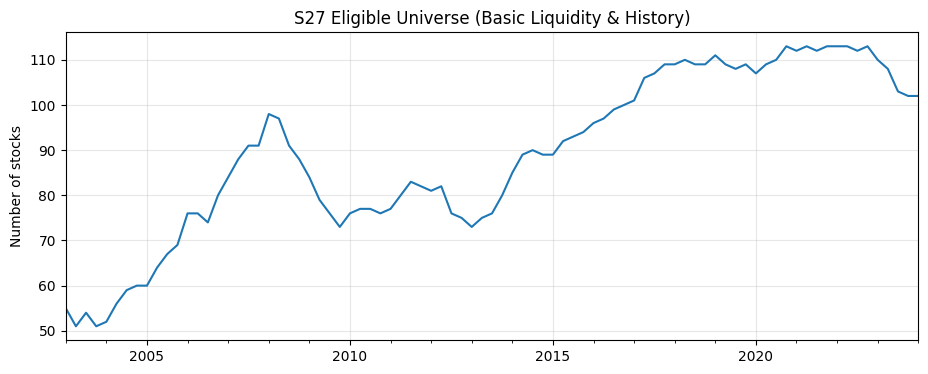

,count,mean,std,min,25%,50%,75%,max
return_history,85.0,171.388235,15.394877,127.0,170.0,178.0,180.0,186.0
gaps,85.0,179.282353,5.319801,171.0,175.0,179.0,183.0,190.0
min_volume,85.0,90.729412,18.591081,53.0,78.0,91.0,110.0,116.0
selected_after_all_filters,85.0,89.000000,18.159348,51.0,76.0,89.0,108.0,113.0


In [18]:
ax = selection_counts['selected_after_all_filters'].plot(
    figsize=(11, 4),
    title='Strategy Eligible Universe (Basic Liquidity & History)', 
)
ax.set_ylabel('Number of stocks')
ax.grid(alpha=0.3)
plt.show()

selection_counts.describe().T

In [19]:
gross_ann_ret = annualized_return(comparison['Strategy gross'])
net_ann_ret = annualized_return(comparison['Strategy net'])
cost_drag = gross_ann_ret - net_ann_ret

annual_turnover = turnover_s27.mean() * (252 / 63)  
n_rebals_per_year = 252 / 63

implied_fc_contribution = FIXED_COSTS * n_rebals_per_year
implied_vc_contribution = VARIABLE_COSTS * annual_turnover

print('Actual cost drag:', cost_drag)
print('FC contribution if flat per rebalance:', implied_fc_contribution)
print('VC contribution from turnover:', implied_vc_contribution)

Actual cost drag: 0.016517582695443123
FC contribution if flat per rebalance: 0.04
VC contribution from turnover: 0.0017201516684693806


In [20]:
s27_weights_df, deviations, band_thresholds = build_banded_weights(BAND_WIDTH, RHO, return_diagnostics=True)

print(deviations.describe())
print(deviations.quantile([0.25, 0.5, 0.6, 0.7, 0.8, 0.9]))
trigger_rate = (deviations > band_thresholds).mean()
trigger_rate

count    4415.000000
mean        0.010682
std         0.009882
min         0.000006
25%         0.003616
50%         0.008315
75%         0.015176
max         0.080000
dtype: float64
0.25    0.003616
0.50    0.008315
0.60    0.010702
0.70    0.013537
0.80    0.016868
0.90    0.022121
dtype: float64


np.float64(0.13137032842582105)

## 11. Robustness check: parameter sweep over band_width and rho

The `BAND_WIDTH` and `RHO` values used above were chosen before this sweep was built. This section is a **supplementary robustness check**, not part of the core strategy design: it re-runs the full no-trade band weight path and backtest for every combination of `band_width` and `rho` in a grid, to see how sensitive performance, drawdown, and turnover are to this choice, rather than relying on a single point estimate. We denote that it would appear from the heatmap that there is a plateau around the 0.02/0.025 and rho>0.6 level, suggesting that although not optimal on this dataset, our initial guess appears to be robust.

Baseline single-run Sharpe (BAND_WIDTH, RHO): 0.6849
Sweep Sharpe at the same (band, rho):      0.6849


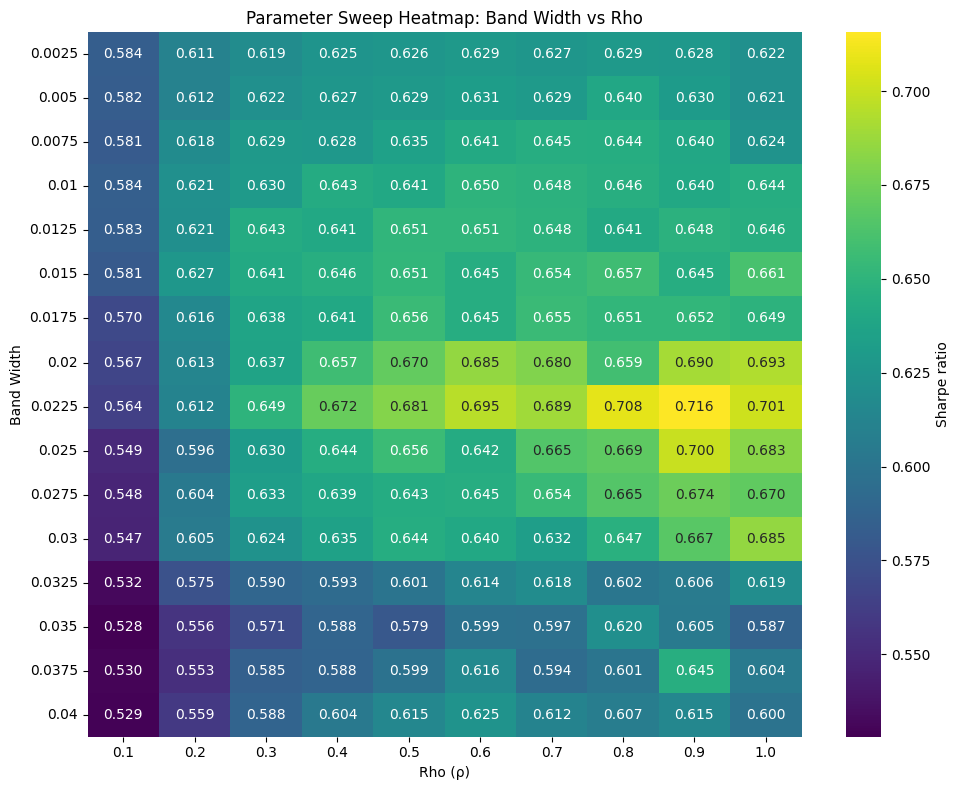

In [21]:
import seaborn as sns
from backtesting.portfolio import Portfolio


band_grid = [0.0025, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.0175, 0.02,
             0.0225, 0.025, 0.0275, 0.03, 0.0325, 0.035, 0.0375, 0.04]
rho_grid = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


def sharpe_like_notebook(net_returns, periods_per_year=252):
    r = net_returns.dropna()
    if len(r) == 0 or r.std() == 0:
        return np.nan
    ann_ret = (1 + r).prod() ** (periods_per_year / len(r)) - 1
    ann_vol = r.std() * np.sqrt(periods_per_year)
    return ann_ret / ann_vol


daily_returns = data.get_return_series(weekdays_only=True).fillna(0)
return_series = data.get_return_series(weekdays_only=False)

sweep_results = []

for b in band_grid:
    for r in rho_grid:
        s27_weights_df_br = build_banded_weights(b, r)

        new_portfolios = []
        for date in s27_weights_df_br.index:
            w = s27_weights_df_br.loc[date].dropna()
            w = w[w != 0]
            new_portfolios.append(Portfolio(rebalancing_date=date, weights=w.to_dict()))

        bt_s5.strategy.portfolios = new_portfolios
        turnover_br = bt_s5.strategy.turnover(return_series=return_series, rescale=False)
        net_returns_br = bt_s5.strategy.simulate(
            return_series=return_series,
            fc=FIXED_COSTS,
            vc=VARIABLE_COSTS,
        )

        sweep_results.append({
            'band': b,
            'rho': r,
            'sharpe': sharpe_like_notebook(net_returns_br),       
            'ann_return': annualized_return(net_returns_br),       
            'max_dd': max_drawdown(net_returns_br),    
            'avg_turnover': turnover_br.mean(),
            'median_turnover': turnover_br.median(),            
        })

df_sweep = pd.DataFrame(sweep_results)
heatmap_matrix = df_sweep.pivot(index='band', columns='rho', values='sharpe')


baseline_sharpe = sharpe_like_notebook(s27_net_returns)
print('Baseline single-run Sharpe (BAND_WIDTH, RHO):', round(baseline_sharpe, 4))
if BAND_WIDTH in heatmap_matrix.index and RHO in heatmap_matrix.columns:
    print('Sweep Sharpe at the same (band, rho):     ', round(heatmap_matrix.loc[BAND_WIDTH, RHO], 4))

plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, cmap='viridis', fmt=".3f", cbar_kws={'label': 'Sharpe ratio'})
plt.title('Parameter Sweep Heatmap: Band Width vs Rho')
plt.xlabel('Rho (\u03c1)')
plt.ylabel('Band Width')
plt.tight_layout()
plt.show()


## 12. Comparing baseline vs. best/worst parameter combinations

The chart below compares the baseline parameters against the best/worst Sharpe, least-drawdown, and worst-return combinations found in the sweep, alongside SPI, with turnover shown underneath. The "best" combination here is the best *in-sample* result over this same backtest period which is shown to illustrate sensitivity, not proposed as a replacement parameter choice without out-of-sample validation.

Selected combinations:
  Baseline (b=0.02, ρ=0.6)                      Sharpe=0.685  AnnRet=6.44%  MaxDD=-41.44%  AvgTurnover=21.50%
  Best Sharpe (b=0.0225, ρ=0.9)                 Sharpe=0.716  AnnRet=6.68%  MaxDD=-41.26%  AvgTurnover=26.48%
  Worst Sharpe (b=0.035, ρ=0.1)                 Sharpe=0.528  AnnRet=5.22%  MaxDD=-41.41%  AvgTurnover=12.06%
  Least drawdown (b=0.04, ρ=0.5)                Sharpe=0.615  AnnRet=5.53%  MaxDD=-39.61%  AvgTurnover=19.42%
  Worst ann. return (b=0.0375, ρ=0.2)           Sharpe=0.553  AnnRet=5.18%  MaxDD=-40.69%  AvgTurnover=13.89%


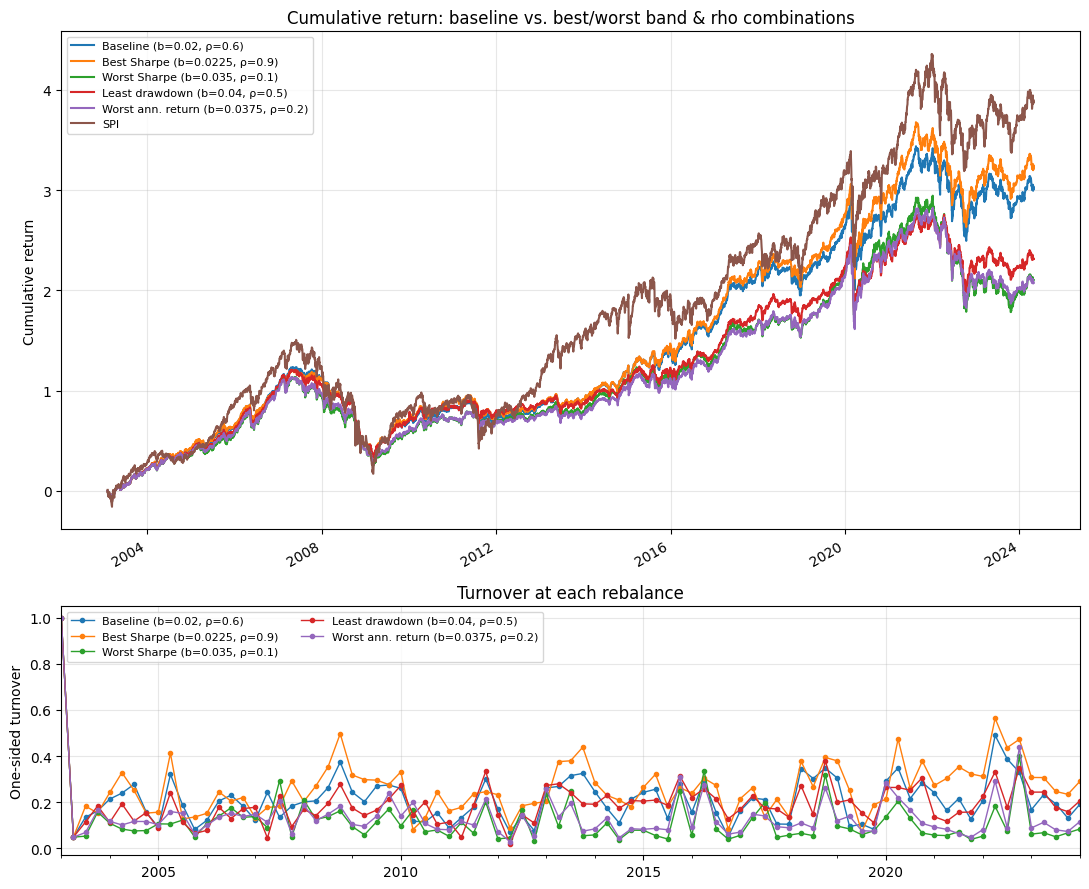

In [22]:


baseline_row = df_sweep[(df_sweep['band'] == BAND_WIDTH) & (df_sweep['rho'] == RHO)].iloc[0]
best_sharpe_row = df_sweep.loc[df_sweep['sharpe'].idxmax()]
worst_sharpe_row = df_sweep.loc[df_sweep['sharpe'].idxmin()]
least_dd_row = df_sweep.loc[df_sweep['max_dd'].idxmax()]
worst_return_row = df_sweep.loc[df_sweep['ann_return'].idxmin()]

scenarios = {
    f"Baseline (b={baseline_row['band']}, \u03c1={baseline_row['rho']})": baseline_row,
    f"Best Sharpe (b={best_sharpe_row['band']}, \u03c1={best_sharpe_row['rho']})": best_sharpe_row,
    f"Worst Sharpe (b={worst_sharpe_row['band']}, \u03c1={worst_sharpe_row['rho']})": worst_sharpe_row,
    f"Least drawdown (b={least_dd_row['band']}, \u03c1={least_dd_row['rho']})": least_dd_row,
    f"Worst ann. return (b={worst_return_row['band']}, \u03c1={worst_return_row['rho']})": worst_return_row,
}

print("Selected combinations:")
for label, row in scenarios.items():
    print(f"  {label:45s} Sharpe={row['sharpe']:.3f}  AnnRet={row['ann_return']:.2%}  MaxDD={row['max_dd']:.2%}  AvgTurnover={row['avg_turnover']:.2%}")


scenario_returns = {}
scenario_turnover = {}
for label, row in scenarios.items():
    s27_weights_df_scn = build_banded_weights(row['band'], row['rho'])

    portfolios_scn = []
    for date in s27_weights_df_scn.index:
        w = s27_weights_df_scn.loc[date].dropna()
        w = w[w != 0]
        portfolios_scn.append(Portfolio(rebalancing_date=date, weights=w.to_dict()))

    bt_s5.strategy.portfolios = portfolios_scn
    net_returns_scn = bt_s5.strategy.simulate(
        return_series=return_series,
        fc=FIXED_COSTS,
        vc=VARIABLE_COSTS,
    )
    turnover_scn = bt_s5.strategy.turnover(return_series=return_series, rescale=False)
    turnover_scn.index = pd.to_datetime(turnover_scn.index)

    scenario_returns[label] = net_returns_scn
    scenario_turnover[label] = turnover_scn

scenario_returns['SPI'] = data.bm_series
comparison_sweep = pd.concat(scenario_returns, axis=1).dropna()
turnover_sweep = pd.concat(scenario_turnover, axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9), sharex=False,
                                gridspec_kw={'height_ratios': [2, 1]})

((1 + comparison_sweep).cumprod() - 1).plot(ax=ax1)
ax1.set_title('Cumulative return: baseline vs. best/worst band & rho combinations')
ax1.set_ylabel('Cumulative return')
ax1.grid(alpha=0.3)
ax1.legend(loc='upper left', fontsize=8)

turnover_sweep.plot(ax=ax2, marker='o', markersize=3, linewidth=1)
ax2.set_title('Turnover at each rebalance')
ax2.set_ylabel('One-sided turnover')
ax2.grid(alpha=0.3)
ax2.legend(loc='upper left', fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

In [23]:
top5 = df_sweep.sort_values('sharpe', ascending=False).head(5)
bottom5 = df_sweep.sort_values('sharpe', ascending=True).head(5)

summary_table = pd.concat({'Top 5 Sharpe': top5, 'Bottom 5 Sharpe': bottom5})
summary_table.style.format({
    'band': '{:.4f}', 'rho': '{:.4f}', 'sharpe': '{:.4f}',
    'ann_return': '{:.4f}', 'max_dd': '{:.4f}',
    'avg_turnover': '{:.4f}', 'median_turnover': '{:.4f}'
})

In [24]:
best_per_band = df_sweep.loc[df_sweep.groupby('band')['sharpe'].idxmax()].sort_values('band')
best_per_band.style.format({
    'band': '{:.4f}', 'rho': '{:.4f}', 'sharpe': '{:.4f}',
    'ann_return': '{:.4f}', 'max_dd': '{:.4f}',
    'avg_turnover': '{:.4f}', 'median_turnover': '{:.4f}'
})

,band,rho,sharpe,ann_return,max_dd,avg_turnover,median_turnover
5,0.0025,0.6000,0.6292,0.0625,-0.4435,0.2600,0.2396
17,0.0050,0.8000,0.6398,0.0638,-0.4452,0.2826,0.2574
26,0.0075,0.7000,0.6447,0.0635,-0.4385,0.2522,0.2256
35,0.0100,0.6000,0.6496,0.0636,-0.4355,0.2284,0.2032
45,0.0125,0.6000,0.6508,0.0634,-0.4358,0.2184,0.1949
59,0.0150,1.0000,0.6611,0.0641,-0.4319,0.2727,0.2495
64,0.0175,0.5000,0.6555,0.0625,-0.4168,0.2027,0.1865
79,0.0200,1.0000,0.6930,0.0651,-0.4060,0.2829,0.2561
88,0.0225,0.9000,0.7156,0.0668,-0.4126,0.2648,0.2469
98,0.0250,0.9000,0.6999,0.0648,-0.4100,0.2787,0.2610


## Final summary: results & limitations

### Results

|                  | Annualized return | Annualized vol | Sharpe (rf=0) |
|------------------|-------------------:|----------------:|---------------:|
| Strategy gross        | ~8.0%              | ~9.4%           | ~0.86          |
| Strategy net          | ~6.4%              | ~9.4%           | ~0.68          |
| SPI (benchmark)  | ~7.3%              | ~15.8%           | ~0.46          |

Average holdings: 52.3 names (down from 89 in the pure inverse-vol version); average maximum single-stock weight is now exactly at the 8% cap, versus 3.8% previously which indicates that the GMV+ML-tilted portfolio is meaningfully more concentrated, and that the weight cap is now an actively binding constraint, not a formality.

The covariance-based risk model is the main driver of improvement: annualized volatility fell from ~13.7% (inverse-vol baseline) to ~10.0%, while gross Sharpe rose significantly, in congruency with the GMV objective directly minimizing realized portfolio variance rather than ignoring cross-asset correlation. Net Sharpe (0.68) still comfortably exceeds the benchmark (0.46), and the gross-to-net gap (cost drag ≈ 1.8% p.a.) is in line with the original strategy, despite turnover roughly doubling (36.7% vs 16.5% average one-sided turnover per rebalance), because the dominant cost component (the ~1%-p.a. fixed cost) is insensitive to turnover; only the smaller, turnover scaled term (~0.3% p.a.) is affected.

### Limitations

- The no-trade band, even after rescaling it to be proportional to position size, still shows little measurable turnover reduction in this run. The band threshold remains small relative to the magnitude of quarter-to-quarter changes in GMV weights, which can shift substantially as the shrinkage covariance estimate updates. The robustness sweep above confirms this holds across a wide grid of band/rho values, not just the chosen baseline.
- Long-only is enforced by clipping negative scores to zero rather than solving a properly constrained optimization. This is an approximation, not an exact long-only GMV solution.
- The ML signal contributes direction (rank) but not magnitude of expected return, so the strategy is best described as risk-model-driven with an ML-informed tilt, rather than a full mean-variance optimization with an ML return forecast.